# Results section 1 and Figure 2

## Setup

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

warnings.filterwarnings("ignore")
%matplotlib inline

def _root(start=None):
    # package root = the folder that holds Data/
    here = Path(__file__).resolve() if "__file__" in globals() else Path.cwd().resolve()
    for c in (here, *here.parents):
        if (c / "Data" / "conversation_turns.csv").exists():
            return c
    raise RuntimeError(f"cannot find the package root (no Data/conversation_turns.csv at or above {here})")

ROOT   = _root()
CLEAN  = ROOT / "Data"
FIGDIR = ROOT / "Code" / "_output" / "figures"; FIGDIR.mkdir(parents=True, exist_ok=True)
RESDIR = ROOT / "Code" / "_output" / "results"; RESDIR.mkdir(parents=True, exist_ok=True)

COL = {"partner": "#00798C", "own": "#D1495B", "solo": "#2B4C7E",
       "grey": "#6E6E6E", "light": "#BFBFBF", "third": "#E8871A"}
SINGLE, DOUBLE = 3.46, 7.09

mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 6.5, "axes.labelsize": 7, "axes.titlesize": 7.5,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "lines.linewidth": 1.3, "lines.markersize": 3.5,
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02, "pdf.fonttype": 42, "ps.fonttype": 42,
})

def panel(ax, letter, title=None, dx=None, dy=None):
    # letter at the axes' left edge, in figure coordinates
    fg = ax.figure; bb = ax.get_position()
    fg.text(bb.x0, bb.y1 + .014, letter, fontsize=8, fontweight="bold",
            va="bottom", ha="left")
    if title:
        # title 0.135 in to the right of the letter
        fg.text(bb.x0 + 0.135 / fg.get_size_inches()[0], bb.y1 + .014, title,
                fontsize=6.8, va="bottom", ha="left", color="#2A2A2A")

def close_corner(fig):
    # pull each lower axis limit in to the first tick when no data lies below it
    for ax in fig.axes:
        if not ax.axison:
            continue
        for get_lim, set_lim, ticks_of, data_lo in (
                (ax.get_xlim, ax.set_xlim, ax.get_xticks, lambda: ax.dataLim.x0),
                (ax.get_ylim, ax.set_ylim, ax.get_yticks, lambda: ax.dataLim.y0)):
            lo, hi = get_lim()
            if hi <= lo:
                continue
            inside = [t for t in ticks_of() if lo <= t <= hi]
            if not inside:
                continue
            first = min(inside)
            if first <= lo:
                continue
            d = data_lo()
            if d != d or d < first + (hi - lo) * 0.03:
                continue
            set_lim(first, hi)
        ax.spines["left"].set_bounds(*ax.get_ylim())
        ax.spines["bottom"].set_bounds(*ax.get_xlim())

def save(fig, name):
    fig.savefig(FIGDIR / f"{name}.pdf")
    fig.savefig(FIGDIR / f"{name}.tif", dpi=300, pil_kwargs={"compression": "tiff_lzw"})
    print(f"wrote {name}.pdf and .tif to Code/_output/figures/")

### Statistical helpers

In [2]:
def paired_effect(x, y, unit_label, names=("first", "second")):
    d_ = np.asarray(y) - np.asarray(x)
    n = len(d_); m_, sd_ = d_.mean(), d_.std(ddof=1)
    se = sd_ / np.sqrt(n)
    tc = stats.t.ppf(0.975, n - 1)
    t = stats.ttest_rel(y, x)
    print(f"    {names[1]} - {names[0]} = {m_:+.3f}   95% CI "
          f"[{m_ - tc*se:+.3f}, {m_ + tc*se:+.3f}]   "
          f"t({n-1}) = {t.statistic:+.2f}, p = {t.pvalue:.1e}")
    print(f"    Cohen's dz = {m_ / sd_:+.2f}   ({unit_label}, n = {n})")
    return m_, m_ / sd_

def raincloud(ax, groups, colors, labels=None, width=.32, jitter=.075, ms=2.6,
              seed=0, alpha_pts=.40):
    # half density right, points left, quartile bar and median between
    rg = np.random.default_rng(seed)
    for i, (vals, c) in enumerate(zip(groups, colors)):
        v = np.asarray(vals, float); v = v[np.isfinite(v)]
        if len(v) > 4 and v.std() > 0:
            kde = stats.gaussian_kde(v)
            grid = np.linspace(v.min() - .05 * np.ptp(v), v.max() + .05 * np.ptp(v), 200)
            dd = kde(grid); dd = dd / dd.max() * width
            ax.fill_betweenx(grid, i + .07, i + .07 + dd, color=c, alpha=.28, lw=0, zorder=2)
            ax.plot(i + .07 + dd, grid, color=c, lw=.7, zorder=3)
        x = i - .13 - np.abs(rg.normal(0, jitter, len(v)))
        ax.scatter(x, v, s=ms, color=c, alpha=alpha_pts, edgecolors="none", zorder=2)
        q1, med, q3 = np.percentile(v, [25, 50, 75])
        ax.plot([i, i], [q1, q3], color=c, lw=3.2, solid_capstyle="butt", zorder=5)
        ax.plot([i], [med], "o", color="white", ms=2.8, mec=c, mew=.7, zorder=6)
    ax.set_xticks(range(len(groups)))
    if labels:
        ax.set_xticklabels(labels)
    ax.set_xlim(-.55, len(groups) - .45)

## 1 · Recall streams

In [3]:
STIMULI = pd.read_csv(CLEAN / "stimuli.csv")
RECALL  = pd.read_csv(CLEAN / "individual_recall.csv")
_st = STIMULI[~STIMULI.is_lure]
ID2CAT = {int(i): int(l) for i, l in zip(_st.item_id, _st.list)}

# recall stream in output order; category for studied words and lures, None for intrusions
pre = RECALL[RECALL.phase == "pre"].sort_values(["participant", "output_position"])
SEQ = {}
for pid, g in pre.groupby("participant"):
    SEQ[str(pid)] = [None if k == "other" else int(l)
                     for k, l in zip(g.kind, g.list)]
print(f"{len(ID2CAT)} studied words in {_st.list.nunique()} lists")
print(f"  {len(SEQ)} first individual recalls")

def runs_in(seq):
    # maximal runs of the same category; None ends a run
    out, cur = [], []
    for i, c in enumerate(seq):
        if c is None:
            if cur:
                out.append(cur); cur = []
            continue
        if cur and seq[cur[-1]] == c:
            cur.append(i)
        else:
            if cur:
                out.append(cur)
            cur = [i]
    if cur:
        out.append(cur)
    return out

100 studied words in 10 lists
  170 first individual recalls


## 2 · Patches in individual recall

In [4]:
rows = []
for pid, cats in SEQ.items():
    # store = studied words only (a lure continues a run but is not counted)
    g = pre[pre.participant == pid]
    stud = [int(l) if k == "studied" else None for k, l in zip(g.kind, g.list)]
    total = pd.Series([c for c in stud if c is not None]).value_counts().to_dict()
    for n, block in enumerate(runs_in(cats)):
        start, cat = block[0], cats[block[0]]
        produced = sum(1 for j in range(start) if stud[j] == cat)
        in_block = sum(1 for j in block if stud[j] == cat)
        # words of this category still to come after the opening word
        opener = int(stud[start] == cat)
        rows.append(dict(pid=pid, category=str(cat), position=n, start=start,
                         # undefined for the last production of a recall
                         length=len(block),
                         survives=int(len(block) > 1) if start < len(cats) - 1 else np.nan,
                         left=total.get(cat, 0) - produced - opener,
                         left_after=total.get(cat, 0) - produced - in_block,
                         revisits=sum(1 for j in range(block[-1] + 1, len(cats))
                                      if cats[j] == cat),
                         pos_frac=start / max(len(cats) - 1, 1),
                         n_words=len(cats)))
IPATCH = pd.DataFrame(rows)
IPATCH["L"] = IPATCH.length.clip(upper=4)
IPATCH.to_csv(RESDIR / "individual_patches.csv", index=False)

ct = IPATCH.pivot_table(index="pid", columns="L", values="position",
                        aggfunc="size").fillna(0)
ct.columns = [int(c) for c in ct.columns]
ct["total"] = ct.sum(1)

## 3 · Comparison with shuffled recall

In [5]:
rngi = np.random.default_rng(3)
NP = 400

# the whole stream is shuffled, intrusions included
def depth_of(seq):
    r = runs_in(seq)
    return sum(len(b) for b in r) / len(r)

def continuation_of(seq):
    # scored only after words whose category recurs later in the recall
    pts = [seq[i + 1] == c for i, c in enumerate(seq[:-1])
           if c is not None and any(x == c for x in seq[i + 1:])]
    return float(np.mean(pts)) if pts else np.nan

def excluded_share(seq):
    # share of category words (studied or lure) that are the last of their category
    w = [i for i, c in enumerate(seq) if c is not None]
    return sum(1 for i in w if not any(x == seq[i] for x in seq[i + 1:])) / len(w)

rows = []
for pid, v in SEQ.items():
    if sum(c is not None for c in v) < 8:
        continue
    nd, na = [], []
    for _ in range(NP):
        p = [v[i] for i in rngi.permutation(len(v))]
        nd.append(depth_of(p)); na.append(continuation_of(p))
    rows.append(dict(pid=pid, depth=depth_of(v), depth_null=float(np.mean(nd)),
                     adj=continuation_of(v), adj_null=float(np.nanmean(na))))
INULL = pd.DataFrame(rows)
print(f"{len(INULL)} people, {NP} shuffles each\n")
print(f"  patch depth  observed {INULL.depth.mean():.3f}   shuffled {INULL.depth_null.mean():.3f}")
_ = paired_effect(INULL.depth_null, INULL.depth, "person as the unit", ("shuffled", "observed"))
_ex = np.array([excluded_share(v) for v in SEQ.values() if any(c is not None for c in v)])
print(f"\n  last word of their category (not scored): "
      f"mean {_ex.mean():.1%} (SD {_ex.std(ddof=1):.1%}), n = {len(_ex)}")
print(f"  continuation  observed {INULL.adj.mean():.3f}   "
      f"shuffled {INULL.adj_null.mean():.3f}")
_ = paired_effect(INULL.adj_null, INULL.adj, "person as the unit", ("shuffled", "observed"))

168 people, 400 shuffles each

  patch depth  observed 2.200   shuffled 1.145
    observed - shuffled = +1.055   95% CI [+0.942, +1.168]   t(167) = +18.49, p = 2.9e-42
    Cohen's dz = +1.43   (person as the unit, n = 168)

  last word of their category (not scored): mean 27.4% (SD 8.2%), n = 170
  continuation  observed 0.683   shuffled 0.167
    observed - shuffled = +0.516   95% CI [+0.489, +0.542]   t(167) = +38.16, p = 2.2e-84
    Cohen's dz = +2.94   (person as the unit, n = 168)


## 4 · Split-half reliability of patch depth

In [6]:
rows = []
for pid, g in IPATCH.sort_values(["pid", "position"]).groupby("pid"):
    if len(g) < 6:
        continue
    g = g.reset_index(drop=True); h = len(g) // 2
    rows.append(dict(pid=pid, n=len(g), h1=g.length[:h].mean(), h2=g.length[h:].mean(),
                     odd=g[g.index % 2 == 0].length.mean(),     # 1st, 3rd, 5th ... patch
                     even=g[g.index % 2 == 1].length.mean(),
                     depth=g.length.mean(), words=g.n_words.iloc[0],
                     cats=g.category.nunique()))
TRAIT = pd.DataFrame(rows)
print(f"{len(TRAIT)} people with at least six patches\n")

def rel(a, b, lab):
    r = stats.pearsonr(TRAIT[a], TRAIT[b])
    print(f"  {lab:<38} r = {r[0]:+.3f}  p = {r[1]:.1e}   "
          f"Spearman-Brown {2*r[0]/(1+r[0]):.3f}")
rel("odd", "even", "odd against even patches")
ra =smf.ols("odd ~ words + cats", TRAIT).fit().resid
rb = smf.ols("even ~ words + cats", TRAIT).fit().resid
pr = stats.pearsonr(ra, rb)
_dfp = len(TRAIT) - 4                       # two covariates partialled out
_tp = pr[0] * np.sqrt(_dfp / (1 - pr[0] ** 2))
print(f"    odd against even, words and lists partialled out: r = {pr[0]:+.3f}, "
      f"p = {2 * stats.t.sf(abs(_tp), _dfp):.1e} (df = {_dfp}), "
      f"Spearman-Brown {2*pr[0]/(1+pr[0]):.3f}")

166 people with at least six patches

  odd against even patches               r = +0.602  p = 1.0e-17   Spearman-Brown 0.751
    odd against even, words and lists partialled out: r = +0.588, p = 1.3e-16 (df = 162), Spearman-Brown 0.740


## 5 · Shuffled benchmark for panel c

In [7]:
rngn = np.random.default_rng(11)
PAIRS = {}
for pid, g in pre.groupby("participant"):
    PAIRS[str(pid)] = [(None if k == "other" else int(l), int(l) if k == "studied" else None)
                       for k, l in zip(g.kind, g.list)]

def _patches(stream):
    rows = []
    for pid, pairs in stream.items():
        cats = [c for c, _ in pairs]; stud = [s for _, s in pairs]
        total = pd.Series([c for c in stud if c is not None]).value_counts().to_dict()
        for block in runs_in(cats):
            start, cat = block[0], cats[block[0]]
            rows.append(dict(pid=pid, survives=int(len(block) > 1),
                             left=total.get(cat, 0) - sum(1 for j in range(start + 1)
                                                          if stud[j] == cat)))
    return pd.DataFrame(rows)

def _binned(P):
    P = P[P.left >= 1]
    q = (P.assign(bb=P.left.clip(upper=4)).groupby(["pid", "bb"])
         .survives.agg(["mean", "size"]).reset_index())
    return q[q["size"] >= 2].groupby("bb")["mean"].mean()

# same number of shuffles as above
NSH = NP
_draws = pd.concat([_binned(_patches({k: [v[i] for i in rngn.permutation(len(v))]
                                      for k, v in PAIRS.items()}))
                    for _ in range(NSH)], axis=1).T
NULLC = pd.DataFrame({"mean": _draws.mean(), "lo": _draws.quantile(.025),
                      "hi": _draws.quantile(.975)})
(RESDIR / "supp").mkdir(exist_ok=True)
NULLC.to_csv(RESDIR / "supp" / "s_store_null_bins.csv")
print(f"shuffled benchmark for panel c, {NSH} shuffles")
print(NULLC.round(3).to_string())

shuffled benchmark for panel c, 400 shuffles
     mean     lo     hi
bb                     
1   0.149  0.125  0.174
2   0.159  0.133  0.189
3   0.168  0.137  0.203
4   0.205  0.171  0.239


## 6 · Figure 2

continuation by words left, mean across participants [95% CI]:
  1   0.559  [0.506, 0.612]  n = 130
  2   0.685  [0.628, 0.741]  n = 112
  3   0.745  [0.689, 0.801]  n = 100
  4+  0.795  [0.755, 0.833]  n = 122
wrote Figure_2.pdf and .tif to Code/_output/figures/


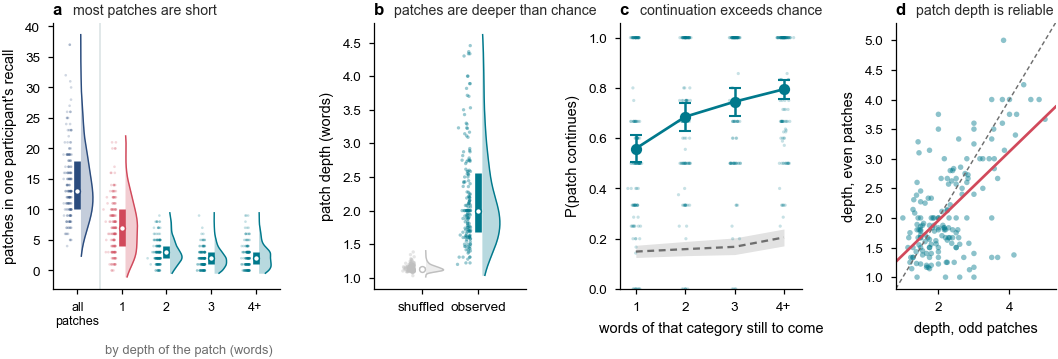

In [8]:
# four panels in one row
fig = plt.figure(figsize=(DOUBLE, 2.45))
gs1 = fig.add_gridspec(1, 4, width_ratios=[1.42, 0.95, 1.14, 1.00], wspace=.52,
                       left=.052, right=.995, top=.94, bottom=.215)
ax = [fig.add_subplot(gs1[0, i]) for i in range(4)]

# ---- a · patches per participant, by depth ----
pc = ax[0]
cols = [c for c in ("total", 1, 2, 3, 4) if c in ct.columns]
raincloud(pc, [ct[c].values for c in cols],
          [COL["solo"], COL["own"], COL["partner"], COL["partner"], COL["partner"]][:len(cols)],
          ["all\npatches", "1", "2", "3", "4+"][:len(cols)],
          seed=0, ms=1.6, alpha_pts=.22, width=.28)
pc.set_ylabel("patches in one participant's recall")
pc.axvline(.5, color="#DCE4E5", lw=.8, zorder=0)
pc.text(2.5, -.205, "by depth of the patch (words)", transform=pc.get_xaxis_transform(),
        ha="center", va="top", fontsize=6.2, color=COL["grey"])
pc.tick_params(axis="x", labelsize=6.0)
panel(pc, "a", "most patches are short", dx=-0.34)

# ---- b · observed vs shuffled depth ----
sh = ax[1]
raincloud(sh, [INULL.depth_null.values, INULL.depth.values],
          [COL["light"], COL["partner"]], ["shuffled", "observed"], seed=1)
sh.set_ylabel("patch depth (words)")
sh.set_xlim(-.85, 1.85)
panel(sh, "b", "patches are deeper than chance", dx=-0.34)

# ---- c · continuation by words left, per person ----
c = ax[2]
# openings with at least one word of the category still to come
d = IPATCH[IPATCH.left >= 1].copy()
d["pid"] = d.pid.astype(str); d["category"] = d.category.astype(str)
pb = (d.assign(bb=d.left.clip(upper=4)).groupby(["pid", "bb"])
      .survives.agg(["mean", "size"]).reset_index())
pb = pb[pb["size"] >= 2]
rgc = np.random.default_rng(21)
est, lo_, hi_, ns = [], [], [], []
for b_ in sorted(pb.bb.unique()):
    v = pb[pb.bb == b_]["mean"].values
    c.scatter(b_ + rgc.normal(0, .055, len(v)), v, s=2.4, color=COL["partner"],
              alpha=.22, edgecolors="none", zorder=2)
    bs = [np.mean(rgc.choice(v, len(v), replace=True)) for _ in range(3000)]
    est.append(v.mean()); lo_.append(np.percentile(bs, 2.5))
    hi_.append(np.percentile(bs, 97.5)); ns.append(len(v))
xs_ = sorted(pb.bb.unique())
print("continuation by words left, mean across participants [95% CI]:")
for b_, e_, l_, h_, n_ in zip(xs_, est, lo_, hi_, ns):
    print(f"  {int(b_)}{'+' if b_ == 4 else ' '}  {e_:.3f}  [{l_:.3f}, {h_:.3f}]  n = {n_}")
c.errorbar(xs_, est, yerr=[np.array(est) - lo_, np.array(hi_) - est], fmt="o-",
           color=COL["partner"], ms=4.4, capsize=3, elinewidth=1.2, zorder=6)
c.fill_between(NULLC.index, NULLC.lo, NULLC.hi, color=COL["grey"], alpha=.20,
               lw=0, zorder=1)
c.plot(NULLC.index, NULLC["mean"], color=COL["grey"], lw=1.1, ls=(0, (3, 2)), zorder=3)
c.set_ylim(0, 1.06)
c.set_xticks(xs_); c.set_xticklabels([str(int(k)) if k < 4 else "4+" for k in xs_])
c.set_xlabel("words of that category still to come")
c.set_ylabel("P(patch continues)")
panel(c, "c", "continuation exceeds chance", dx=-0.34)

# ---- d · odd vs even patch depth ----
e = ax[3]
e.scatter(TRAIT.odd, TRAIT.even, s=7, color=COL["partner"], alpha=.45, edgecolors="none")
lims = [.8, max(TRAIT.odd.max(), TRAIT.even.max()) + .3]
e.plot(lims, lims, color=COL["grey"], lw=.7, ls=(0, (3, 2)))
sl, ic = np.polyfit(TRAIT.odd, TRAIT.even, 1)
xs2 = np.linspace(*lims, 50)
e.plot(xs2, sl * xs2 + ic, color=COL["own"], lw=1.3)
e.set_xlim(lims); e.set_ylim(lims)
e.set_xlabel("depth, odd patches")
e.set_ylabel("depth, even patches")
panel(e, "d", "patch depth is reliable", dx=-0.34)

close_corner(fig)
save(fig, "Figure_2"); plt.show()